# Chapitre 4 - Cours 6 : flux de données par messages, courtiers et acteurs

Troisième mode de flux de données, à mi-chemin entre la base et le service : des
**messages asynchrones**. Comme un appel RPC, un message part vers un autre processus
avec une faible latence ; comme une écriture en base, il ne lui est pas remis
directement, mais confié à un intermédiaire, le **courtier** (message broker), qui le
stocke temporairement. Ce cours couvre la section *Message-Passing Dataflow*
(*Message brokers*, *Distributed actor frameworks*) et conclut le chapitre.

**Plan.**

1. Des messages plutôt que des appels.
2. Un courtier de messages écrit à la main : tampon, files et sujets, redistribution.
3. Encodage et évolution des messages : registre de schémas et republication.
4. Les frameworks d'acteurs distribués.

In [1]:
import collections
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. Des messages plutôt que des appels (section *Message-Passing Dataflow*)

Dans ce mode, une requête s'appelle un **message**. Contrairement au RPC,
l'expéditeur n'attend en général pas que le destinataire l'ait traité ; et le message ne
passe pas par une connexion réseau directe, mais par un **courtier** (aussi appelé file de
messages, ou intergiciel orienté messages) qui le conserve temporairement. Le livre
énumère les avantages d'un courtier par rapport au RPC direct :

1. il sert de **tampon** si le destinataire est indisponible ou surchargé ;
2. il peut **redistribuer** les messages à un processus qui a planté, au lieu de les
   perdre ;
3. l'expéditeur n'a pas besoin de connaître l'adresse du destinataire (pas de
   découverte de services) ;
4. un même message peut aller à **plusieurs** destinataires ;
5. il **découple** logiquement l'expéditeur du destinataire : l'un publie, sans se
   soucier de qui consomme.

La communication est **asynchrone** : l'expéditeur envoie et oublie. On peut toutefois
imiter un RPC en attendant une réponse sur un canal séparé (section 2).

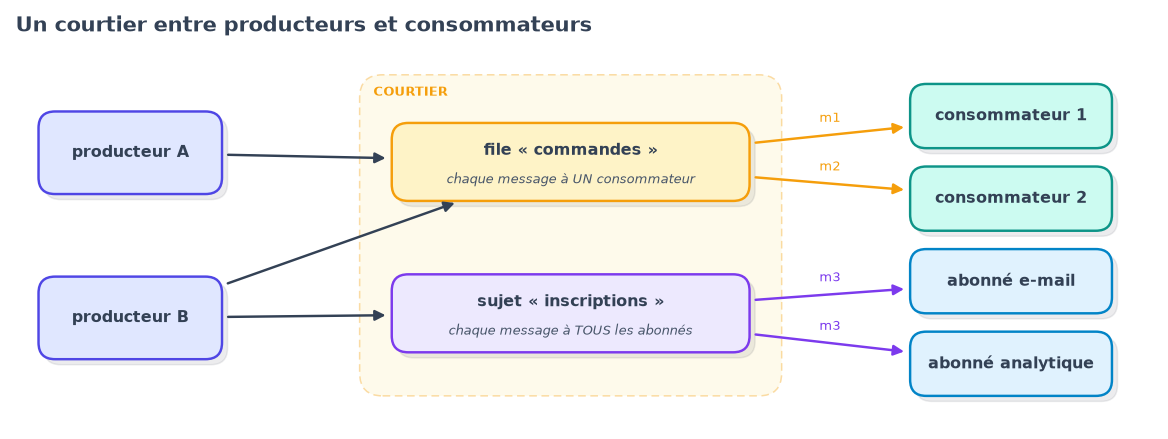

In [2]:
d = Diagram(12.5, 4.0, title="Un courtier entre producteurs et consommateurs")
d.box("p1", 1.3, 3.0, "producteur A", color=INDIGO, w=2.0)
d.box("p2", 1.3, 1.2, "producteur B", color=INDIGO, w=2.0)
d.group(3.8, 0.35, 8.4, 3.85, "courtier", color=AMBER)
d.box("q", 6.1, 2.9, "file « commandes »", sub="chaque message à UN consommateur", color=AMBER, w=3.9, h=0.85)
d.box("t", 6.1, 1.25, "sujet « inscriptions »", sub="chaque message à TOUS les abonnés", color=VIOLET, w=3.9, h=0.85)
d.box("c1", 10.9, 3.4, "consommateur 1", color=TEAL, w=2.2, h=0.7)
d.box("c2", 10.9, 2.5, "consommateur 2", color=TEAL, w=2.2, h=0.7)
d.box("s1", 10.9, 1.6, "abonné e-mail", color=SKY, w=2.2, h=0.7)
d.box("s2", 10.9, 0.7, "abonné analytique", color=SKY, w=2.2, h=0.7)
d.arrow("p1", "q"); d.arrow("p2", "q"); d.arrow("p2", "t")
d.arrow("q", "c1", "m1", color=AMBER); d.arrow("q", "c2", "m2", color=AMBER)
d.arrow("t", "s1", "m3", color=VIOLET); d.arrow("t", "s2", "m3", color=VIOLET)
d.show()

> **À retenir.** Un message est encodé par l'expéditeur, confié à un courtier, puis
> décodé par un ou plusieurs destinataires, de façon asynchrone. Le courtier sert de
> tampon, redistribue après une panne, découple les deux côtés et permet la diffusion.